# Polynomial fits: Part 1

## Linear least squares

Linear least squares refers to the problem of minimizing $\chi^2$ with a model that can be written as a linear combination of *basis functions* $f_j(x)$ as 

$$m(x) = \sum_{j=1}^M a_j f_j(x)$$

where $a_j$ are the model parameters. For example, if we wanted to fit a polynomial we would choose $f_j(x) = x^{j-1}$ and minimize $\chi^2$ to find the polynomial coefficients $\{a_j\}$. A straight-line fit has $f_0=1$ and $f_1=x$.

The linear least squares problem can be written in the form of "matrix times vector equals matrix times vector" as follows:
$$\mathbf{A^T} \mathbf{d} = \mathbf{A^T}\mathbf{A}\mathbf{a},$$
which are known as the **normal equations**. Here, the vector $\mathbf{d}$ is the data weighted by the errors at each point,
$$d_i = {y_i\over\sigma_i},$$
and 
$$A_{ij} = {f_j(x_i)\over \sigma_i}$$
is known as the *design matrix*. Notice that the design matrix has a column for each basis function $f_j$, and a row $i$ for each data point. The normal equations tell us how to use the data $\mathbf{d}$ to obtain the fitting coefficients $\mathbf{a}$.

:::{seealso} Derivation of the normal equations
:class: dropdown
To derive the normal equations, write out $\chi^2$ and minimize it:

$$\chi^2 = \sum_{i=1}^N \left[ {y_i - \sum_{j=1}^M a_j f_j(x_i)\over \sigma_i}\right]^2$$

$${\partial \chi^2\over\partial a_k} = 0 \Rightarrow \sum_{i=1}^N {1\over\sigma_i^2}\left[ y_i - \sum_{j=1}^M a_j f_j(x_i)\right] f_k(x_i) = 0$$

$$\sum_{i=1}^N {y_i\over\sigma_i}{f_k(x_i)\over\sigma_i} - \sum_{i=1}^N\sum_{j=1}^M a_k {f_j(x_i)\over\sigma_i }{f_k(x_i)\over \sigma_i} = 0$$

Now rewrite this in terms of $\mathbf{d}$ defined above and the design matrix:

$$\sum_{i=1}^N A_{ik} b_i - \sum_{i=1}^N\sum_{j=1}^M a_k A_{ij}A_{ik} = 0$$

$$\sum_{i=1}^N (A^T)_{ki} b_i  - \sum_{j=1}^M \sum_{i=1}^N  (A^T)_{ji}A_{ik} a_k  = 0$$

So in matrix form, we have 

$$\mathbf{A^T} \mathbf{d} = \mathbf{A^T}\mathbf{A}\mathbf{a}.$$
:::

:::{note}
We've assumed here that the noise is uncorrelated between measurements. In this case, the covariance matrix is diagonal with elements $C_{ii} = \sigma_i^2$. If the noise is correlated, the covariance between different measurements can be accounted for by writing 
$$\chi^2 = (\mathbf{y} - \mathbf{F}\mathbf{a})^T\mathbf{C}^{-1}\left(\mathbf{y}-\mathbf{F}\mathbf{a}\right)$$ where $F_{ij}=f_j(x_i)$ is the unweighted design matrix and $C_{ij}$ is the noise covariance matrix. For simplicity here, we will stick to uncorrelated noise and focus on how we can solve the normal equations.
:::

:::{tip} Exercise
A good way to play around with these equation is to show that $\chi^2$ can be written in our matrix notation as 
$$\chi^2 = (\mathbf{d} - \mathbf{A}\mathbf{a})^T  (\mathbf{d} - \mathbf{A}\mathbf{a}).$$
:::

## Polynomial fits

We're going to look at the example of fitting a polynomial to some measurements $y_i(x_i)$ (ie. $y$ measured at a set of points $x_i$). An obvious way to solve the normal equations

$$\mathbf{A^T} \mathbf{d} = \mathbf{A^T}\mathbf{A}\mathbf{a}$$ 

is to calculate the inverse of $\mathbf{A^T}\mathbf{A}$ and write

$$\mathbf{a} = (\mathbf{A^T}\mathbf{A})^{-1} \mathbf{A^T} \mathbf{d}.$$

For simplicity, let's take a constant error $\sigma_i$ for each point, so the $\sigma_i$'s cancel out of the equations (it's straightforward to put them back in if you need to). 

Polynomial order, Polynomial coeffs, Fitted coeffs, Fractional error
x^0     -0.647798     -0.662439     0.0226016
x^1     -0.843393     -0.850405    0.00831386
x^2     -0.953271     -0.946382   -0.00722647
x^3      0.302766      0.305364    0.00857957
reduced chi2 = 1.14896


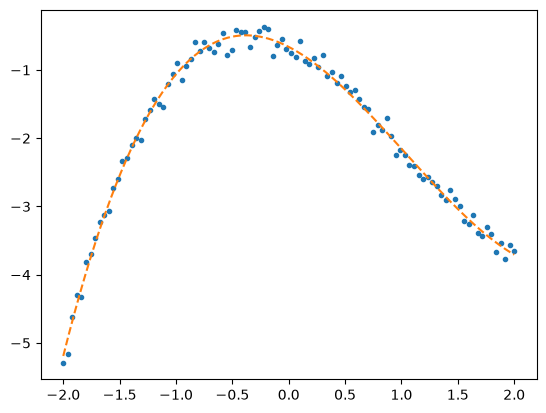

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# first generate some data from a random polynomial

k = 3 # order of polynomial
n = 100  # number of data points
sigma = 0.1 # noise

x = np.linspace(-2,2,n)
# generate random coefficients, each between -1 and 1
a0 = -1.0 + 2*np.random.rand(k+1)
# generate the polynomial and add some noise
poly = np.polynomial.Polynomial(a0)
y = poly(x) + np.random.normal(scale=sigma, size=n)
plt.plot(x,y,'.')

# Compute the design matrix
# A_{ij} = f_j(x_i)
A = np.zeros((n, k+1))
for kk in range(k+1):
    A[:, kk] = x**kk

# We could also use:
# A = np.vander(x, N=k+1, increasing=True)

# Now do the linear algebra part 
rhs = np.transpose(A)@y
lhs = np.transpose(A)@A
a = np.linalg.inv(lhs)@rhs

print("Polynomial order, Polynomial coeffs, Fitted coeffs, Fractional error")
for i in range(k+1):
    print("x^%d %13g %13g %13g" % (i, a0[i], a[i], (a[i]-a0[i])/a0[i]))

# Plot the fitted polynomial on top of the original
xx = np.linspace(-2,2,1000)
poly = np.polynomial.Polynomial(a)
yy = poly(xx)
plt.plot(xx,yy,'--')

if sigma>0.0:
    chi2 = np.mean((y-poly(x))**2)/sigma**2
else:
    chi2 = np.mean((y-poly(x))**2)
print('reduced chi2 = %g' % (chi2,))

plt.show()


:::{tip} Exercise
Try running this code. What happens to the fractional error in the fitted coefficients if you take the noise to zero?

With the noise at zero, try increasing the polynomial order $k$. What happens as $k$ grows larger?
:::